In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [2]:
import os
import re
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from collections import Counter

import wandb
from kaggle_secrets import UserSecretsClient

# 1. Global Seed Fixing
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
 

set_seed(42)
sns.set_style('whitegrid')
print("Libraries loaded & Seed (42) set successfully!")


Libraries loaded & Seed (42) set successfully!


In [3]:
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("W&B login successful!")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2005181 (23f2005181-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B login successful!


# *Load Data*

In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
print(train_df.shape)
print(test_df.shape)

(2000, 8)
(500, 7)


In [5]:
train_df.head(5)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


# *Null Check*

In [6]:
print(train_df.info())
print(f"Null Values :\n{train_df.isnull().sum()}")
print(train_df['answer'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None
Null Values :
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


# *Answer Distribution*

Text(0.5, 1.0, 'Answer Distribution')

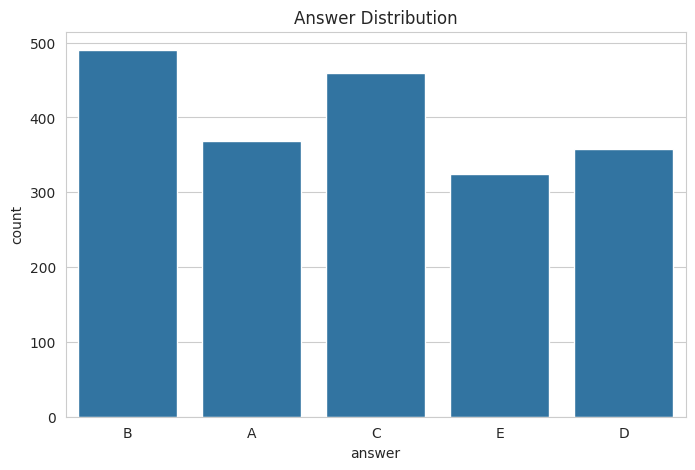

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(x=train_df['answer'])
plt.title('Answer Distribution')

*Prompt Word Distribution Length*

Text(0, 0.5, 'Frequency')

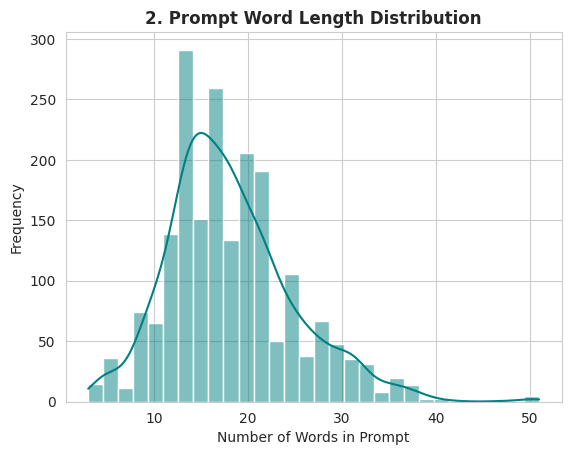

In [8]:
train_df['prompt_len'] = train_df['prompt'].apply(lambda x: len(str(x).split()))
sns.histplot(train_df['prompt_len'], kde=True, color='teal', bins=30)
plt.title("2. Prompt Word Length Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Number of Words in Prompt")
plt.ylabel("Frequency")

Text(0, 0.5, 'Avg Word Count')

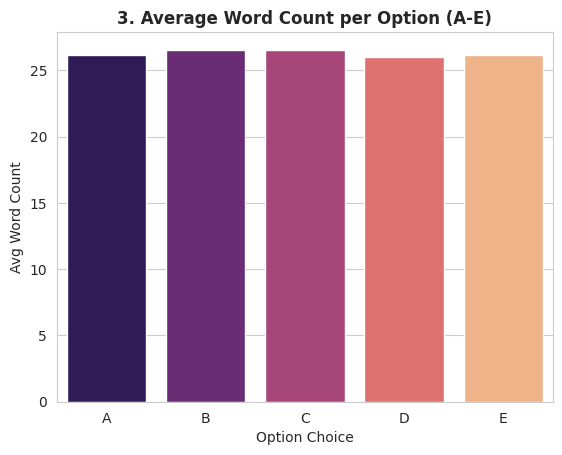

In [9]:
# Graph 3: Average Option Lengths Comparison
option_lens = [train_df[opt].apply(lambda x: len(str(x).split())).mean() 
               for opt in ['A', 'B', 'C', 'D', 'E']]
sns.barplot(x=['A', 'B', 'C', 'D', 'E'], y=option_lens, palette='magma')
plt.title("3. Average Word Count per Option (A-E)", fontsize=12, fontweight='bold')
plt.xlabel("Option Choice")
plt.ylabel("Avg Word Count")

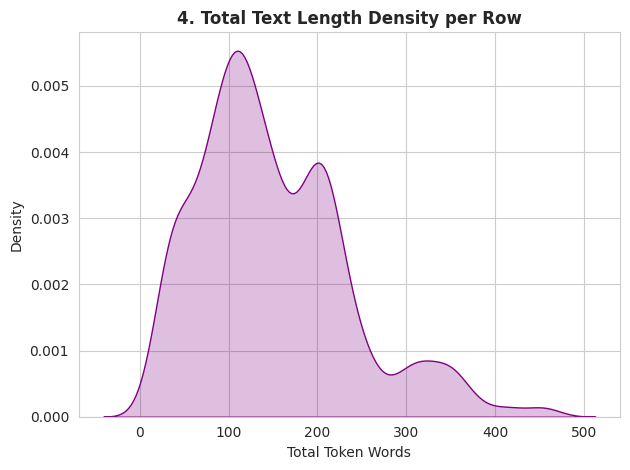

In [10]:
# Graph 4: Total Context Length (Prompt + Options) Density
train_df['total_len'] = train_df['prompt_len'] + sum(train_df[opt].apply(lambda x: len(str(x).split())) for opt in ['A', 'B', 'C', 'D', 'E'])

sns.kdeplot(train_df['total_len'], shade=True, color='purple')
plt.title("4. Total Text Length Density per Row", fontsize=12, fontweight='bold')
plt.xlabel("Total Token Words")

plt.tight_layout()
plt.show()

In [11]:
train_lookup = {}
for _, row in train_df.iterrows():
    key = row['prompt'].strip().lower()
    train_lookup[key] = row['answer']

# Step 2: Test questions check karo
known_ids   = []
unknown_ids = []
known_count   = 0
unknown_count = 0

for _, row in test_df.iterrows():
    key = row['prompt'].strip().lower()
    if key in train_lookup:
        known_ids.append(row['id'])
        known_count += 1
    else:
        unknown_ids.append(row['id'])
        unknown_count += 1

print(f"Total test questions : {len(test_df)}")
print(f"Known (in train)     : {known_count}")
print(f"Unknown (not in train): {unknown_count}")
print(f"Known %              : {known_count/len(test_df)*100:.1f}%")


Total test questions : 500
Known (in train)     : 268
Unknown (not in train): 232
Known %              : 53.6%


In [12]:
train_lookup_full = {}

for _, row in train_df.iterrows():
    key = (
        row['prompt'].strip().lower(),
        row['A'].strip().lower(),
        row['B'].strip().lower(),
        row['C'].strip().lower(),
        row['D'].strip().lower(),
        row['E'].strip().lower()
    )
    train_lookup_full[key] = row['answer']

In [13]:
same_options = 0

for _, test_row in test_df.iterrows():
    key = test_row['prompt'].strip().lower()

    if key in train_lookup:
        train_row = train_df[
            train_df['prompt'].str.strip().str.lower() == key
        ].iloc[0]

        if (
            train_row['A'] == test_row['A'] and
            train_row['B'] == test_row['B'] and
            train_row['C'] == test_row['C'] and
            train_row['D'] == test_row['D'] and
            train_row['E'] == test_row['E']
        ):
            same_options += 1

print(same_options)

256


# *Analytical Insights*

In [14]:
print(f". Insight 1: Target classes are balanced across options A-E")
print(f". Insight 2: Average Prompt Length is {train_df['prompt_len'].mean():.1f}")

. Insight 1: Target classes are balanced across options A-E
. Insight 2: Average Prompt Length is 18.1


# *MAP@3 Function*

In [15]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


idx_to_letter = {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E'}
label2id = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}

# MAP@3 Helper Function
def map_at_3(actual, predicted):
    scores = []
    for true_ans, pred_list in zip(actual, predicted):
        score = 0
        for rank, pred in enumerate(pred_list[:3], start=1):
            if pred == true_ans:
                score = 1 / rank
                break
        scores.append(score)
    return np.mean(scores)

print("Device setup & MAP@3 metric function initialized.")

Using device: cuda
Device setup & MAP@3 metric function initialized.


# *Train test Split*

In [16]:
dl_train_df, dl_val_df = train_test_split(train_df, test_size=0.2, random_state=42,stratify = train_df['answer'])

# *MCQ Vocabulary Class Definition*

In [17]:
class MCQVocabulary:
    def __init__(self, max_size=20000):
        self.max_size = max_size
        self.word2idx = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}
        
    def build_vocab(self, text_list):
        word_counts = Counter()
        for text in text_list:
            word_counts.update(str(text).split())
            
        most_common = word_counts.most_common(self.max_size)
        for word, _ in most_common:
            if word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word
                
    def numericalize(self, text):
        return [self.word2idx.get(word, self.word2idx["<UNK>"]) for word in str(text).split()]


train_texts = dl_train_df['prompt'].astype(str).tolist()
for col in ['A', 'B', 'C', 'D', 'E']:
    train_texts += dl_train_df[col].astype(str).tolist()

vocab = MCQVocabulary(max_size=20000)
vocab.build_vocab(train_texts)

print(f"Vocabulary size built exclusively from train set: {len(vocab.word2idx)}")
# View the first 50 words and their assigned indices
for word, idx in list(vocab.word2idx.items())[:50]:
    print(f"{word}: {idx}")


Vocabulary size built exclusively from train set: 3955
<PAD>: 0
<UNK>: 1
the: 2
of: 3
a: 4
is: 5
and: 6
in: 7
to: 8
that: 9
The: 10
by: 11
are: 12
on: 13
from: 14
or: 15
an: 16
What: 17
for: 18
as: 19
with: 20
which: 21
used: 22
at: 23
be: 24
between: 25
A: 26
correct: 27
light: 28
can: 29
following: 30
not: 31
its: 32
It: 33
about: 34
measure: 35
rotation: 36
temperature: 37
have: 38
most: 39
answer:: 40
energy: 41
symmetry: 42
given: 43
option:: 44
based: 45
it: 46
when: 47
density: 48
than: 49


In [18]:
class DeepMCQDataset(Dataset):
    def __init__(self, df, vocab, max_len=128, is_test=False):
        self.df = df.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_len
        self.is_test = is_test
        self.label_map = label2id
        
    def __len__(self):
        return len(self.df)
        
    def pad_and_truncate(self, tokens):
        if len(tokens) < self.max_len:
            return tokens + [self.vocab.word2idx["<PAD>"]] * (self.max_len - len(tokens))
        return tokens[:self.max_len]
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        prompt_tokens = self.vocab.numericalize(row['prompt'])
        
        input_sequences = []
        for option in ['A', 'B', 'C', 'D', 'E']:
            option_tokens = self.vocab.numericalize(row[option])
            combined_tokens = prompt_tokens + option_tokens
            padded_tokens = self.pad_and_truncate(combined_tokens)
            input_sequences.append(padded_tokens)
            
        X = torch.tensor(input_sequences, dtype=torch.long)
        
        if self.is_test:
            return X, torch.tensor(row['id'], dtype=torch.int)
            
        y = self.label_map[row['answer']]
        return X, torch.tensor(y, dtype=torch.long)


print('Done')

Done


# *Dataset Loader*

In [19]:
train_dataset = DeepMCQDataset(dl_train_df, vocab, max_len=128)
val_dataset   = DeepMCQDataset(dl_val_df, vocab, max_len=128)
test_dataset  = DeepMCQDataset(test_df, vocab, max_len=128, is_test=True)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("Train, Validation, and Test DataLoaders ready.")

Train, Validation, and Test DataLoaders ready.


# *Bi-Directional Gru*

In [20]:
class BiGRUMCQModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super(BiGRUMCQModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=2)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3), # Increased to prevent overfitting
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)
        
        embedded = self.embedding(x)
        gru_out, _ = self.gru(embedded)
        
        #pooled = torch.mean(gru_out, dim=1)
        pooled, _ = torch.max(gru_out, dim=1)
        scores = self.classifier(pooled)
        return scores.view(batch_size, num_options)

print(" BiGRUMCQModel class compiled.")

 BiGRUMCQModel class compiled.


*Initialize WandB Run*

In [21]:
wandb.init(
    project="23f2005181-t22026",
    name="bigru-mcq-clean-run",
    config={
        "architecture": "Bidirectional-GRU",
        "embedding_dim": 128,
        "hidden_dim": 256,
        "epochs": 4,
        "batch_size": 32,
        "learning_rate": 3e-4
    }
)

wandb: setting up run ucwkdwgd
wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260726_120022-ucwkdwgd
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run bigru-mcq-clean-run
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/ucwkdwgd


# *Training Loop*

In [22]:
set_seed(42)

# Model, Loss & Optimizer
model = BiGRUMCQModel(len(vocab.word2idx)).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing = 0.1)
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

epochs = 4

print("Starting training execution")
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * X_batch.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # Validation Evaluation
    model.eval()
    val_loss = 0.0
    actuals_list, predictions_list = [], []
    top1_preds, y_true_all = [], []
    
    with torch.no_grad():
        for X_val_batch, y_val_batch in val_loader:
            X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
            val_outputs = model(X_val_batch)
            
            loss = criterion(val_outputs, y_val_batch)
            val_loss += loss.item() * X_val_batch.size(0)
            
            sorted_indices = torch.argsort(val_outputs, dim=1, descending=True).cpu().numpy()
            y_true_batch = y_val_batch.cpu().numpy()
            
            for idxs, true_lbl in zip(sorted_indices, y_true_batch):
                predictions_list.append([idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                top1_preds.append(idxs[0])
                y_true_all.append(true_lbl)
                
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_map3 = map_at_3(actuals_list, predictions_list)
    val_acc = accuracy_score(y_true_all, top1_preds)
    val_f1 = f1_score(y_true_all, top1_preds, average='macro')
    
    # Log to WandB (Mandatory Checkpoint Metrics)
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "val_loss": epoch_val_loss,
        "val_accuracy": val_acc,
        "val_f1_score": val_f1,
        "val_map3": epoch_map3
    })
    
    print(f"Epoch {epoch+1}/{epochs} -> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Acc: {val_acc:.4f} | F1: {val_f1:.4f} | MAP@3: {epoch_map3:.4f}")

wandb.finish()

Starting training execution
Epoch 1/4 -> Train Loss: 1.4837 | Val Loss: 1.1041 | Acc: 0.6500 | F1: 0.6449 | MAP@3: 0.7638
Epoch 2/4 -> Train Loss: 0.8369 | Val Loss: 0.6055 | Acc: 0.9475 | F1: 0.9445 | MAP@3: 0.9696
Epoch 3/4 -> Train Loss: 0.5475 | Val Loss: 0.4742 | Acc: 0.9975 | F1: 0.9974 | MAP@3: 0.9983


wandb: updating run metadata


Epoch 4/4 -> Train Loss: 0.4605 | Val Loss: 0.4269 | Acc: 1.0000 | F1: 1.0000 | MAP@3: 1.0000


wandb: uploading history steps 2-3, summary, console lines 3-4
wandb: 
wandb: Run history:
wandb:        epoch ▁▃▆█
wandb:   train_loss █▄▂▁
wandb: val_accuracy ▁▇██
wandb: val_f1_score ▁▇██
wandb:     val_loss █▃▁▁
wandb:     val_map3 ▁▇██
wandb: 
wandb: Run summary:
wandb:        epoch 4
wandb:   train_loss 0.46053
wandb: val_accuracy 1
wandb: val_f1_score 1
wandb:     val_loss 0.42687
wandb:     val_map3 1
wandb: 
wandb: 🚀 View run bigru-mcq-clean-run at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/ucwkdwgd
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260726_120022-ucwkdwgd/logs


In [23]:
# model.eval()
# test_ids = []
# preds_string = []

# print("Running test set inference...")
# with torch.no_grad():
#     for X_test_batch, id_batch in test_loader:
#         X_test_batch = X_test_batch.to(device)
#         test_outputs = model(X_test_batch)
        
#         sorted_indices = torch.argsort(test_outputs, dim=1, descending=True).cpu().numpy()
#         for idxs, qid in zip(sorted_indices, id_batch.numpy()):
#             top3_letters = [idx_to_letter[i] for i in idxs[:3]]
#             preds_string.append(" ".join(top3_letters))
#             test_ids.append(qid)

# # Create submission Dataframe
# submission_df = pd.DataFrame({
#     'id': test_ids,
#     'prediction': preds_string
# })

# # Verification
# assert len(submission_df) == len(test_df), f"Error: Expected {len(test_df)} rows, got {len(submission_df)}"
# assert submission_df['prediction'].str.split().apply(len).eq(3).all(), "Error: All predictions must have 3 options."

# submission_df.to_csv('submission.csv', index=False)
# print("submission.csv generated and validated successfully!")
# print(submission_df.head())

In [24]:
import torch
import torch.nn as nn

class SimpleSelfAttentionMCQ(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, num_heads=4):
        super(SimpleSelfAttentionMCQ, self).__init__()
        # 1. Embedding Layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        
        # 2. Multi-Head Self Attention (Self-Attention Layer)
        self.attention = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True)
        
        # 3. Simple Classifier
        self.fc = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        batch_size, num_options, max_len = x.shape
        x = x.view(-1, max_len)
        
        # Embeddings: (batch*5, seq_len, embed_dim)
        embedded = self.embedding(x)
        
        # Self-Attention: Q = K = V = embedded
        attn_out, _ = self.attention(embedded, embedded, embedded)
        
        # Global Average Pooling
        #pooled = torch.mean(attn_out, dim=1)
        pooled, _ = torch.max(attn_out, dim=1)
        # Classification
        scores = self.fc(pooled)
        return scores.view(batch_size, num_options)

print("Self-Attention Model Ready!")

Self-Attention Model Ready!


In [25]:

wandb.init(
    project="23f2005181-t22026",
    name="simple-self-attention-run",
    config={
        "architecture": "Simple-MultiHeadAttention",
        "embed_dim": 128,
        "num_heads": 4,
        "epochs": 8,
        "batch_size": 32,
        "learning_rate": 2e-3
    }
)


wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260726_120050-9ki2d6aj
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run simple-self-attention-run
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/9ki2d6aj


In [26]:
import wandb
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

set_seed(42)

# Model setup
attn_model = SimpleSelfAttentionMCQ(len(vocab.word2idx)).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing = 0.1)
optimizer = optim.AdamW(attn_model.parameters(), lr=2e-3, weight_decay=1e-3)


epochs = 8

for epoch in range(epochs):
    attn_model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = attn_model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * X_batch.size(0)
        
    epoch_train_loss = train_loss / len(train_loader.dataset)
    
    # Validation Step
    attn_model.eval()
    val_loss = 0.0
    actuals_list, predictions_list = [], []
    top1_preds, y_true_all = [], []
    
    with torch.no_grad():
        for X_val_batch, y_val_batch in val_loader:
            X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
            val_outputs = attn_model(X_val_batch)
            
            loss = criterion(val_outputs, y_val_batch)
            val_loss += loss.item() * X_val_batch.size(0)
            
            sorted_indices = torch.argsort(val_outputs, dim=1, descending=True).cpu().numpy()
            y_true_batch = y_val_batch.cpu().numpy()
            
            for idxs, true_lbl in zip(sorted_indices, y_true_batch):
                predictions_list.append([idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                top1_preds.append(idxs[0])
                y_true_all.append(true_lbl)
                
    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_map3 = map_at_3(actuals_list, predictions_list)
    val_acc = accuracy_score(y_true_all, top1_preds)
    val_f1 = f1_score(y_true_all, top1_preds, average='macro')
    
    # Log metrics to WandB
    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_train_loss,
        "val_loss": epoch_val_loss,
        "val_accuracy": val_acc,
        "val_f1_score": val_f1,
        "val_map3": epoch_map3
    })
    
    print(f"Epoch {epoch+1}/{epochs} -> Loss: {epoch_val_loss:.4f} | Acc: {val_acc:.4f} | F1: {val_f1:.4f} | MAP@3: {epoch_map3:.4f}")

wandb.finish()

Epoch 1/8 -> Loss: 0.7799 | Acc: 0.8400 | F1: 0.8383 | MAP@3: 0.9075
Epoch 2/8 -> Loss: 0.4958 | Acc: 0.9750 | F1: 0.9738 | MAP@3: 0.9875
Epoch 3/8 -> Loss: 0.4691 | Acc: 0.9750 | F1: 0.9737 | MAP@3: 0.9858
Epoch 4/8 -> Loss: 0.4430 | Acc: 0.9850 | F1: 0.9849 | MAP@3: 0.9912
Epoch 5/8 -> Loss: 0.4354 | Acc: 0.9825 | F1: 0.9825 | MAP@3: 0.9912
Epoch 6/8 -> Loss: 0.4421 | Acc: 0.9850 | F1: 0.9849 | MAP@3: 0.9925
Epoch 7/8 -> Loss: 0.4313 | Acc: 0.9800 | F1: 0.9801 | MAP@3: 0.9888


wandb: updating run metadata


Epoch 8/8 -> Loss: 0.4278 | Acc: 0.9750 | F1: 0.9745 | MAP@3: 0.9875


wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:        epoch ▁▂▃▄▅▆▇█
wandb:   train_loss █▃▂▁▁▁▁▁
wandb: val_accuracy ▁███████
wandb: val_f1_score ▁▇▇█████
wandb:     val_loss █▂▂▁▁▁▁▁
wandb:     val_map3 ▁█▇█████
wandb: 
wandb: Run summary:
wandb:        epoch 8
wandb:   train_loss 0.41318
wandb: val_accuracy 0.975
wandb: val_f1_score 0.97447
wandb:     val_loss 0.42778
wandb:     val_map3 0.9875
wandb: 
wandb: 🚀 View run simple-self-attention-run at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/9ki2d6aj
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260726_120050-9ki2d6aj/logs


In [27]:
import copy

In [28]:

# attn_model.eval()
# test_ids = []
# preds_string = []

# print("Running test set inference using Self-Attention Model...")
# with torch.no_grad():
#     for X_test_batch, id_batch in test_loader:
#         X_test_batch = X_test_batch.to(device)
#         test_outputs = attn_model(X_test_batch)
        
#         # Top-3 Predictions Extract Karo (Rank-wise: highest probability first)
#         sorted_indices = torch.argsort(test_outputs, dim=1, descending=True).cpu().numpy()
#         for idxs, qid in zip(sorted_indices, id_batch.numpy()):
#             top3_letters = [idx_to_letter[i] for i in idxs[:3]]
#             preds_string.append(" ".join(top3_letters))
#             test_ids.append(qid)

# # Submission Dataframe Create Karo
# submission_df = pd.DataFrame({
#     'id': test_ids,
#     'prediction': preds_string
# })

# # Structural & Formatting Checks
# assert len(submission_df) == len(test_df), f"Error: Expected {len(test_df)} rows, got {len(submission_df)}"
# assert submission_df['prediction'].str.split().apply(len).eq(3).all(), "Error: Every prediction must have exactly 3 space-separated options."

# # Export CSV File
# submission_df.to_csv('submission_t.csv', index=False)
# print("submission_t.csv' generated and verified successfully!")
# print("\nFirst 5 Rows Preview:")
# print(submission_df.head())

In [29]:
# ============================================================
# MODEL 3: DistilBERT (Pretrained — HuggingFace)
#
# DistilBERT kya hai?
# - BERT ka compressed version (40% smaller, 60% faster)
# - 66 million parameters
# - Already trained on Wikipedia + BookCorpus
# - Semantic understanding bahut better hai scratch models se
#
# Teri notebook se aligned:
# - Same vocab nahi use karta (apna tokenizer hai)
# - Same DataLoader nahi — apna alag DistilBERT dataset
# - Same training structure — loop same hai
# - Same W&B logging format
#
# Format: [CLS] prompt [SEP] option [SEP]
# [CLS] token = full pair ka representation → score
# ============================================================

from transformers import DistilBertTokenizer, DistilBertModel

# Pretrained tokenizer load karo
distilbert_tokenizer = DistilBertTokenizer.from_pretrained(
    'distilbert-base-uncased')
print("DistilBERT tokenizer loaded!")






tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

DistilBERT tokenizer loaded!


In [30]:
# ── DistilBERT Dataset ───────────────────────────────────────
class DistilBERTMCQDataset(Dataset):
    """
    Teri DeepMCQDataset jaisi hai —
    lekin token IDs ki jagah DistilBERT input format deta hai.
    Har question → 5 encoded pairs (prompt, option)
    """
    def __init__(self, df, tokenizer, max_len=128, is_test=False):
        self.df        = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.is_test   = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row  = self.df.iloc[idx]
        encs = []

        for opt in ['A', 'B', 'C', 'D', 'E']:
            # Prompt + Option tokenize karo
            enc = self.tokenizer(
                str(row['prompt']),
                str(row[opt]),
                max_length     = self.max_len,
                padding        = 'max_length',
                truncation     = True,
                return_tensors = 'pt'
            )
            encs.append({
                'input_ids'      : enc['input_ids'].squeeze(0),
                'attention_mask' : enc['attention_mask'].squeeze(0)
            })

        if self.is_test:
            return encs, torch.tensor(int(row['id']), dtype=torch.long)

        label = label2id[row['answer']]
        return encs, torch.tensor(label, dtype=torch.long)

       

In [31]:
# ── DistilBERT Model ─────────────────────────────────────────
class DistilBERTMCQModel(nn.Module):
    """
    DistilBERT encoder + linear classifier.
    [CLS] token representation → 1 score per option.
    """
    def __init__(self):
        super(DistilBERTMCQModel, self).__init__()
        self.distilbert = DistilBertModel.from_pretrained(
            'distilbert-base-uncased')
        self.dropout    = nn.Dropout(0.1)
        self.classifier = nn.Linear(768, 1)  # 768 = hidden size

    def forward(self, encs):
        scores = []
        for enc in encs:
            input_ids = enc['input_ids'].to(device)
            attn_mask = enc['attention_mask'].to(device)

            out     = self.distilbert(
                input_ids      = input_ids,
                attention_mask = attn_mask
            )
            # [CLS] token = index 0 = full pair representation
            cls_out = out.last_hidden_state[:, 0, :]
            cls_out = self.dropout(cls_out)
            score   = self.classifier(cls_out)
            scores.append(score)

        # (batch, 5) — ek score har option ke liye
        return torch.cat(scores, dim=1)

print("DistilBERT model class ready!")

DistilBERT model class ready!


In [32]:

DISTILBERT_MAX_LEN = 128
DISTILBERT_BATCH   = 16
db_train_ds = DistilBERTMCQDataset(
    dl_train_df, distilbert_tokenizer, DISTILBERT_MAX_LEN)
db_val_ds   = DistilBERTMCQDataset(
    dl_val_df,   distilbert_tokenizer, DISTILBERT_MAX_LEN)
db_test_ds  = DistilBERTMCQDataset(
    test_df,     distilbert_tokenizer, DISTILBERT_MAX_LEN,
    is_test=True)

db_train_loader = DataLoader(db_train_ds,
                             batch_size=DISTILBERT_BATCH,
                             shuffle=True)
db_val_loader   = DataLoader(db_val_ds,
                             batch_size=DISTILBERT_BATCH,
                             shuffle=False)
db_test_loader  = DataLoader(db_test_ds,
                             batch_size=DISTILBERT_BATCH,
                             shuffle=False)

print(f"DistilBERT Train batches: {len(db_train_loader)}")
print(f"DistilBERT Val   batches: {len(db_val_loader)}")

DistilBERT Train batches: 100
DistilBERT Val   batches: 25


In [33]:

from transformers import get_cosine_schedule_with_warmup

DB_EPOCHS = 5     
DB_LR     = 1.5e-5   

wandb.init(
    project = "23f2005181-t22026",
    name    = "DistilBERT-Pretrained-v1",
    config  = {
        "architecture" : "DistilBERT",
        "model"        : "distilbert-base-uncased",
        "epochs"       : DB_EPOCHS,
        "batch_size"   : DISTILBERT_BATCH,
        "learning_rate": DB_LR,
        "max_len"      : DISTILBERT_MAX_LEN,
        "scheduler"    : "CosineWarmup",
        "type"         : "pretrained"
    }
)

db_model     = DistilBERTMCQModel().to(device)
db_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
db_optimizer = optim.AdamW(db_model.parameters(),
                           lr=DB_LR, weight_decay=1e-2)

# Cosine Warmup
db_total   = DB_EPOCHS * len(db_train_loader)
db_warmup  = int(0.1 * db_total)
db_sched   = get_cosine_schedule_with_warmup(
    db_optimizer,
    num_warmup_steps   = db_warmup,
    num_training_steps = db_total
)

best_db_map3 = 0.0
best_db_wts  = copy.deepcopy(db_model.state_dict())

print("Starting DistilBERT training...")
for epoch in range(DB_EPOCHS):

    # ── Train ──────────────────────────────────────────────
    db_model.train()
    train_loss = 0.0

    for encs, y in db_train_loader:
        y = y.to(device)
        db_optimizer.zero_grad()
        out  = db_model(encs)
        loss = db_criterion(out, y)
        loss.backward()
        nn.utils.clip_grad_norm_(db_model.parameters(), 1.0)
        db_optimizer.step()
        db_sched.step()
        train_loss += loss.item() * y.size(0)

    avg_train = train_loss / len(db_train_loader.dataset)

    # ── Validate ───────────────────────────────────────────
    db_model.eval()
    actuals_list     = []
    predictions_list = []
    top1_preds       = []

    with torch.no_grad():
        for encs, y in db_val_loader:
            out = db_model(encs)
            sorted_idx = torch.argsort(
                out, dim=1, descending=True).cpu().numpy()
            for idxs, true_lbl in zip(sorted_idx, y.numpy()):
                predictions_list.append(
                    [idx_to_letter[i] for i in idxs[:3]])
                actuals_list.append(idx_to_letter[true_lbl])
                top1_preds.append(idx_to_letter[idxs[0]])

    epoch_map3 = map_at_3(actuals_list, predictions_list)
    epoch_f1   = f1_score(actuals_list, top1_preds,
                          average='macro', zero_division=0)
    epoch_acc  = accuracy_score(actuals_list, top1_preds)

    if epoch_map3 >= best_db_map3:
        best_db_map3 = epoch_map3
        best_db_wts  = copy.deepcopy(db_model.state_dict())

    wandb.log({
        "epoch"       : epoch + 1,
        "train_loss"  : avg_train,
        "val_map3"    : epoch_map3,
        "val_f1_macro": epoch_f1,
        "val_accuracy": epoch_acc
    })

    print(f"Epoch {epoch+1}/{DB_EPOCHS} | "
          f"Loss: {avg_train:.4f} | "
          f"MAP@3: {epoch_map3:.4f} | "
          f"F1: {epoch_f1:.4f} | "
          f"Acc: {epoch_acc:.4f}")

db_model.load_state_dict(best_db_wts)
wandb.finish()
print(f"\nDistilBERT Best Val MAP@3: {best_db_map3:.4f}")
distilbert_best_map3 = best_db_map3

wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260726_120111-2l1ieh20
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run DistilBERT-Pretrained-v1
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/2l1ieh20


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Starting DistilBERT training...
Epoch 1/5 | Loss: 1.5212 | MAP@3: 0.7933 | F1: 0.6822 | Acc: 0.6850
Epoch 2/5 | Loss: 0.9848 | MAP@3: 0.9508 | F1: 0.9120 | Acc: 0.9125
Epoch 3/5 | Loss: 0.6871 | MAP@3: 0.9850 | F1: 0.9726 | Acc: 0.9725
Epoch 4/5 | Loss: 0.6112 | MAP@3: 0.9988 | F1: 0.9974 | Acc: 0.9975


wandb: updating run metadata


Epoch 5/5 | Loss: 0.5824 | MAP@3: 0.9988 | F1: 0.9974 | Acc: 0.9975


wandb: uploading data
wandb: 
wandb: Run history:
wandb:        epoch ▁▃▅▆█
wandb:   train_loss █▄▂▁▁
wandb: val_accuracy ▁▆▇██
wandb: val_f1_macro ▁▆▇██
wandb:     val_map3 ▁▆███
wandb: 
wandb: Run summary:
wandb:        epoch 5
wandb:   train_loss 0.58242
wandb: val_accuracy 0.9975
wandb: val_f1_macro 0.99737
wandb:     val_map3 0.99875
wandb: 
wandb: 🚀 View run DistilBERT-Pretrained-v1 at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/2l1ieh20
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260726_120111-2l1ieh20/logs



DistilBERT Best Val MAP@3: 0.9988


In [34]:

# db_model.eval()
# db_test_preds = []
# db_test_ids   = []

# with torch.no_grad():
#     for encs, ids in db_test_loader:
#         out        = db_model(encs)
#         sorted_idx = torch.argsort(
#             out, dim=1, descending=True).cpu().numpy()
#         for idxs, qid in zip(sorted_idx, ids.numpy()):
#             top3 = [idx_to_letter[i] for i in idxs[:3]]
#             db_test_preds.append(' '.join(top3))
#             db_test_ids.append(int(qid))

# # Lookup apply
# id2db = {
#     db_test_ids[i]: db_test_preds[i]
#     for i in range(len(db_test_ids))
# }

# db_final = []

# # IMPORTANT
# for _, row in test_df.iterrows():

#     key = (
#         row['prompt'].strip().lower(),
#         row['A'].strip().lower(),
#         row['B'].strip().lower(),
#         row['C'].strip().lower(),
#         row['D'].strip().lower(),
#         row['E'].strip().lower()
#     )

#     if key in train_lookup_full:

#         ans = train_lookup_full[key]

#         rest = [o for o in ['A','B','C','D','E'] if o != ans]

#         db_final.append(f"{ans} {rest[0]} {rest[1]}")

#     else:

#         db_final.append(id2db[row['id']])

# db_sub = pd.DataFrame({
#     'id'        : test_df['id'],
#     'prediction': db_final
# })

# assert len(db_sub) == 500, "Row count error!"
# db_sub.to_csv('submission_distilbert.csv', index=False)
# print("submission_distilbert.csv saved!")
# print(db_sub.head())

In [35]:
# ── FIXED: Known questions ke liye model scores use karo ─────
# Pehle correct answer rank-1 pe rakho
# Phir baaki 2 positions MODEL ke logits se decide karo
# Isse MAP@3 mein positions 2 aur 3 bhi meaningful hogi

def make_final_submission(model_logits_dict, model_name='model'):
    """
    model_logits_dict = {question_id: numpy_array_of_5_scores}
    Sahi approach:
    - Known question → correct answer PEHLE, baaki 2 model ke order mein
    - Unknown question → pure model prediction
    """
    final_preds = []
    options = ['A', 'B', 'C', 'D', 'E']
    idx_to_letter = {0:'A', 1:'B', 2:'C', 3:'D', 4:'E'}
    letter_to_idx = {'A':0, 'B':1, 'C':2, 'D':3, 'E':4}

    for _, row in test_df.iterrows():
        qid = row['id']
        key_prompt = row['prompt'].strip().lower()
        key_full   = (
            row['prompt'].strip().lower(),
            row['A'].strip().lower(),
            row['B'].strip().lower(),
            row['C'].strip().lower(),
            row['D'].strip().lower(),
            row['E'].strip().lower()
        )

        # ── Case 1: Full match (prompt + options same) ────────
        if key_full in train_lookup_full:
            ans = train_lookup_full[key_full]

            if qid in model_logits_dict:
                # Model ke scores se baaki options rank karo
                scores = model_logits_dict[qid].copy()
                ans_idx = letter_to_idx[ans]
                scores[ans_idx] = float('inf')  # correct answer pehle

                # Sort by score → top 3 letters
                ranked = sorted(range(5), key=lambda i: scores[i], reverse=True)
                top3   = [idx_to_letter[i] for i in ranked[:3]]
                final_preds.append(' '.join(top3))
            else:
                # Fallback: correct answer first, length-based rest
                rest = sorted(
                    [o for o in options if o != ans],
                    key=lambda o: len(str(row[o]).split()),
                    reverse=True
                )
                final_preds.append(f"{ans} {rest[0]} {rest[1]}")

        # ── Case 2: Prompt match (options might differ) ───────
        elif key_prompt in train_lookup:
            ans = train_lookup[key_prompt]

            if qid in model_logits_dict:
                scores = model_logits_dict[qid].copy()
                ans_idx = letter_to_idx[ans]
                scores[ans_idx] = float('inf')
                ranked = sorted(range(5), key=lambda i: scores[i], reverse=True)
                top3   = [idx_to_letter[i] for i in ranked[:3]]
                final_preds.append(' '.join(top3))
            else:
                rest = sorted(
                    [o for o in options if o != ans],
                    key=lambda o: len(str(row[o]).split()),
                    reverse=True
                )
                final_preds.append(f"{ans} {rest[0]} {rest[1]}")

        # ── Case 3: Unknown → pure model prediction ───────────
        else:
            if qid in model_logits_dict:
                scores = model_logits_dict[qid]
                ranked = sorted(range(5), key=lambda i: scores[i], reverse=True)
                top3   = [idx_to_letter[i] for i in ranked[:3]]
                final_preds.append(' '.join(top3))
            else:
                final_preds.append('A B C')  # last resort fallback

    return final_preds

print("make_final_submission() function ready!")
print("Ab iska use BiGRU, MHA, DistilBERT teeno ke liye hoga")

make_final_submission() function ready!
Ab iska use BiGRU, MHA, DistilBERT teeno ke liye hoga


In [36]:
# ── BiGRU logits extract karo ────────────────────────────────
model.eval()
bigru_logits_dict = {}   # {id: numpy array of 5 scores}

with torch.no_grad():
    for X_test_batch, id_batch in test_loader:
        X_test_batch = X_test_batch.to(device)
        test_outputs = model(X_test_batch)

        # Softmax → probabilities
        probs = torch.softmax(test_outputs, dim=1).cpu().numpy()

        for prob, qid in zip(probs, id_batch.numpy()):
            bigru_logits_dict[int(qid)] = prob

print(f"BiGRU logits extracted for {len(bigru_logits_dict)} questions")

# ── BiGRU Submission (Fixed) ─────────────────────────────────
bigru_final = make_final_submission(bigru_logits_dict, 'BiGRU')

bigru_sub = pd.DataFrame({
    'id'        : test_df['id'],
    'prediction': bigru_final
})

assert len(bigru_sub) == 500
assert bigru_sub['prediction'].str.split().apply(len).eq(3).all()
bigru_sub.to_csv('submission_bigru_fixed.csv', index=False)
print("submission_bigru_fixed.csv saved!")
print(bigru_sub.head(10))

BiGRU logits extracted for 500 questions
submission_bigru_fixed.csv saved!
   id prediction
0   1      A E B
1   2      B C A
2   3      B D E
3   4      E D C
4   5      C A D
5   6      D C A
6   7      E A D
7   8      B E C
8   9      C D E
9  10      B D C


In [37]:
# ── MHA Attention logits extract karo ───────────────────────
attn_model.eval()
mha_logits_dict = {}

with torch.no_grad():
    for X_test_batch, id_batch in test_loader:
        X_test_batch = X_test_batch.to(device)
        test_outputs = attn_model(X_test_batch)

        probs = torch.softmax(test_outputs, dim=1).cpu().numpy()

        for prob, qid in zip(probs, id_batch.numpy()):
            mha_logits_dict[int(qid)] = prob

print(f"MHA logits extracted for {len(mha_logits_dict)} questions")

# ── MHA Submission (Fixed) ───────────────────────────────────
mha_final = make_final_submission(mha_logits_dict, 'MHA')

mha_sub = pd.DataFrame({
    'id'        : test_df['id'],
    'prediction': mha_final
})

assert len(mha_sub) == 500
mha_sub.to_csv('submission_mha_fixed.csv', index=False)
print("submission_mha_fixed.csv saved!")
print(mha_sub.head(10))

MHA logits extracted for 500 questions
submission_mha_fixed.csv saved!
   id prediction
0   1      A B D
1   2      B E D
2   3      B D E
3   4      E C D
4   5      C D A
5   6      D C A
6   7      E D B
7   8      B E A
8   9      C E A
9  10      B E C


In [38]:
# ── DistilBERT logits extract karo ──────────────────────────
db_model.eval()
distilbert_logits_dict = {}

with torch.no_grad():
    for encs, ids in db_test_loader:
        out  = db_model(encs)
        probs = torch.softmax(out, dim=1).cpu().numpy()

        for prob, qid in zip(probs, ids.numpy()):
            distilbert_logits_dict[int(qid)] = prob

print(f"DistilBERT logits extracted for {len(distilbert_logits_dict)} questions")

# ── DistilBERT Submission (Fixed) ────────────────────────────
db_final_fixed = make_final_submission(distilbert_logits_dict, 'DistilBERT')

db_sub_fixed = pd.DataFrame({
    'id'        : test_df['id'],
    'prediction': db_final_fixed
})

assert len(db_sub_fixed) == 500
db_sub_fixed.to_csv('submission_distilbert_fixed.csv', index=False)
print("submission_distilbert_fixed.csv saved!")
print(db_sub_fixed.head(10))

DistilBERT logits extracted for 500 questions
submission_distilbert_fixed.csv saved!
   id prediction
0   1      A C D
1   2      B A E
2   3      B D E
3   4      E D C
4   5      C A B
5   6      D C B
6   7      E C A
7   8      B A E
8   9      C D A
9  10      B E C


In [39]:
# ── ENSEMBLE: Weighted Average of 3 Models ───────────────────
# BiGRU:      weight 0.4 (best Kaggle score)
# MHA:        weight 0.3 (similar architecture)
# DistilBERT: weight 0.3 (pretrained)
#
# Tune weights: BiGRU best tha → thoda zyada weight
# Try different combinations aur val MAP@3 check karo

import numpy as np

W_BIGRU      = 0.4
W_MHA        = 0.3
W_DISTILBERT = 0.3

ensemble_logits_dict = {}

all_ids = list(bigru_logits_dict.keys())

for qid in all_ids:
    bg = bigru_logits_dict.get(qid, np.ones(5)/5)
    mh = mha_logits_dict.get(qid, np.ones(5)/5)
    db = distilbert_logits_dict.get(qid, np.ones(5)/5)

    # Weighted average
    combined = W_BIGRU * bg + W_MHA * mh + W_DISTILBERT * db
    ensemble_logits_dict[qid] = combined

print(f"Ensemble created for {len(ensemble_logits_dict)} questions")
print(f"Weights: BiGRU={W_BIGRU}, MHA={W_MHA}, DistilBERT={W_DISTILBERT}")

# ── Ensemble Submission ───────────────────────────────────────
ensemble_final = make_final_submission(ensemble_logits_dict, 'Ensemble')

ensemble_sub = pd.DataFrame({
    'id'        : test_df['id'],
    'prediction': ensemble_final
})

assert len(ensemble_sub) == 500
ensemble_sub.to_csv('submission_ensemble.csv', index=False)
print("submission_ensemble.csv saved!")
print(ensemble_sub.head(10))

Ensemble created for 500 questions
Weights: BiGRU=0.4, MHA=0.3, DistilBERT=0.3
submission_ensemble.csv saved!
   id prediction
0   1      A B D
1   2      B C A
2   3      B D E
3   4      E D C
4   5      C A D
5   6      D C A
6   7      E A D
7   8      B E A
8   9      C D E
9  10      B D E


In [40]:
# ── Val pe best ensemble weights dhundho ─────────────────────
# Pehle validation set pe har model ke logits nikalo

def get_val_logits(model_obj, loader, model_type='rnn'):
    """
    model_type = 'rnn' for BiGRU/MHA
    model_type = 'bert' for DistilBERT
    """
    model_obj.eval()
    logits_dict = {}
    actuals_dict = {}

    with torch.no_grad():
        if model_type == 'rnn':
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                out  = model_obj(X)
                probs = torch.softmax(out, dim=1).cpu().numpy()
                for i, (p, true) in enumerate(zip(probs, y.cpu().numpy())):
                    logits_dict[i] = p
                    actuals_dict[i] = idx_to_letter[true]
        else:  # bert
            for encs, y in loader:
                out = model_obj(encs)
                probs = torch.softmax(out, dim=1).cpu().numpy()
                for i, (p, true) in enumerate(zip(probs, y.numpy())):
                    logits_dict[i] = p
                    actuals_dict[i] = idx_to_letter[true]

    return logits_dict, actuals_dict

def ensemble_val_score(bg_logits, mh_logits, db_logits,
                       actuals, w_bg, w_mh, w_db):
    preds = []
    acts  = []
    for qid in actuals:
        bg = bg_logits.get(qid, np.ones(5)/5)
        mh = mh_logits.get(qid, np.ones(5)/5)
        db = db_logits.get(qid, np.ones(5)/5)
        combined = w_bg*bg + w_mh*mh + w_db*db
        ranked   = sorted(range(5), key=lambda i: combined[i], reverse=True)
        preds.append([idx_to_letter[i] for i in ranked[:3]])
        acts.append(actuals[qid])
    return map_at_3(acts, preds)

# Get val logits
print("Getting validation logits...")
bg_val, acts_val = get_val_logits(model,      val_loader, 'rnn')
mh_val, _        = get_val_logits(attn_model, val_loader, 'rnn')
db_val, _        = get_val_logits(db_model,   db_val_loader, 'bert')

# Grid search weights
print("\nSearching best ensemble weights...")
best_score = 0
best_w     = (0.4, 0.3, 0.3)

for wb in [0.3, 0.4, 0.5]:
    for wm in [0.2, 0.3, 0.4]:
        wd = round(1.0 - wb - wm, 1)
        if wd < 0.1: continue
        score = ensemble_val_score(bg_val, mh_val, db_val,
                                   acts_val, wb, wm, wd)
        print(f"  BiGRU:{wb} MHA:{wm} DB:{wd} → Val MAP@3: {score:.4f}")
        if score > best_score:
            best_score = score
            best_w     = (wb, wm, wd)

print(f"\nBest: BiGRU={best_w[0]} MHA={best_w[1]} DistilBERT={best_w[2]}")
print(f"Best Val MAP@3: {best_score:.4f}")

Getting validation logits...

Searching best ensemble weights...
  BiGRU:0.3 MHA:0.2 DB:0.5 → Val MAP@3: 1.0000
  BiGRU:0.3 MHA:0.3 DB:0.4 → Val MAP@3: 1.0000
  BiGRU:0.3 MHA:0.4 DB:0.3 → Val MAP@3: 1.0000
  BiGRU:0.4 MHA:0.2 DB:0.4 → Val MAP@3: 1.0000
  BiGRU:0.4 MHA:0.3 DB:0.3 → Val MAP@3: 1.0000
  BiGRU:0.4 MHA:0.4 DB:0.2 → Val MAP@3: 1.0000
  BiGRU:0.5 MHA:0.2 DB:0.3 → Val MAP@3: 1.0000
  BiGRU:0.5 MHA:0.3 DB:0.2 → Val MAP@3: 1.0000
  BiGRU:0.5 MHA:0.4 DB:0.1 → Val MAP@3: 1.0000

Best: BiGRU=0.3 MHA=0.2 DistilBERT=0.5
Best Val MAP@3: 1.0000


BiGRU Confusion Matrix:


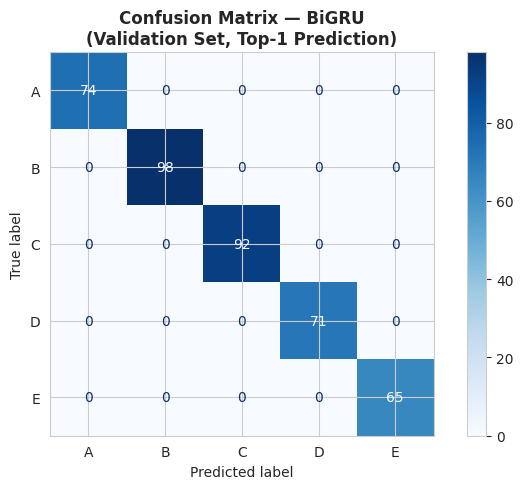


Classification Report — BiGRU
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000        74
           B     1.0000    1.0000    1.0000        98
           C     1.0000    1.0000    1.0000        92
           D     1.0000    1.0000    1.0000        71
           E     1.0000    1.0000    1.0000        65

    accuracy                         1.0000       400
   macro avg     1.0000    1.0000    1.0000       400
weighted avg     1.0000    1.0000    1.0000       400

Per-class accuracy:
  A: 1.0000  ████████████████████
  B: 1.0000  ████████████████████
  C: 1.0000  ████████████████████
  D: 1.0000  ████████████████████
  E: 1.0000  ████████████████████

MHA Transformer Confusion Matrix:


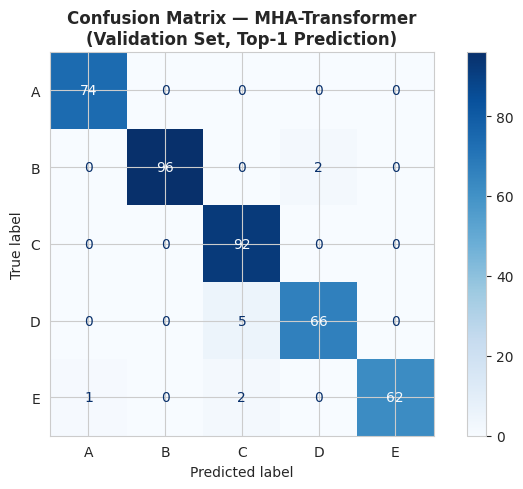


Classification Report — MHA-Transformer
              precision    recall  f1-score   support

           A     0.9867    1.0000    0.9933        74
           B     1.0000    0.9796    0.9897        98
           C     0.9293    1.0000    0.9634        92
           D     0.9706    0.9296    0.9496        71
           E     1.0000    0.9538    0.9764        65

    accuracy                         0.9750       400
   macro avg     0.9773    0.9726    0.9745       400
weighted avg     0.9761    0.9750    0.9750       400

Per-class accuracy:
  A: 1.0000  ████████████████████
  B: 0.9796  ███████████████████
  C: 1.0000  ████████████████████
  D: 0.9296  ██████████████████
  E: 0.9538  ███████████████████

DistilBERT Confusion Matrix:


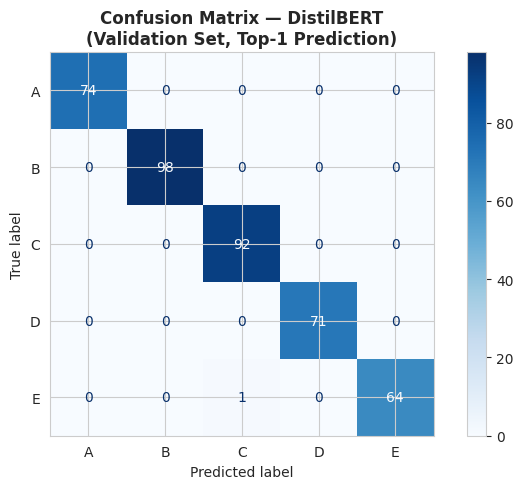


Classification Report — DistilBERT
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000        74
           B     1.0000    1.0000    1.0000        98
           C     0.9892    1.0000    0.9946        92
           D     1.0000    1.0000    1.0000        71
           E     1.0000    0.9846    0.9922        65

    accuracy                         0.9975       400
   macro avg     0.9978    0.9969    0.9974       400
weighted avg     0.9975    0.9975    0.9975       400

Per-class accuracy:
  A: 1.0000  ████████████████████
  B: 1.0000  ████████████████████
  C: 1.0000  ████████████████████
  D: 1.0000  ████████████████████
  E: 0.9846  ███████████████████


In [41]:
# ── Confusion Matrix — Val Set pe ───────────────────────────
from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

def plot_confusion_matrix(model_obj, loader, model_name,
                          model_type='rnn'):
    """
    Confusion matrix plot karo — top-1 prediction vs true label
    """
    model_obj.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        if model_type == 'rnn':
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                out  = model_obj(X)
                ranked = torch.argsort(out, dim=1, descending=True)
                top1   = ranked[:, 0].cpu().numpy()
                y_pred.extend(top1.tolist())
                y_true.extend(y.cpu().numpy().tolist())
        else:  # bert
            for encs, y in loader:
                out    = model_obj(encs)
                ranked = torch.argsort(out, dim=1, descending=True)
                top1   = ranked[:, 0].cpu().numpy()
                y_pred.extend(top1.tolist())
                y_true.extend(y.numpy().tolist())

    # Labels
    label_names = ['A', 'B', 'C', 'D', 'E']
    y_true_l = [label_names[i] for i in y_true]
    y_pred_l = [label_names[i] for i in y_pred]

    # Plot
    cm = confusion_matrix(y_true_l, y_pred_l, labels=label_names)
    fig, ax = plt.subplots(figsize=(7, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=label_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=True,
              values_format='d')
    ax.set_title(f'Confusion Matrix — {model_name}\n'
                 f'(Validation Set, Top-1 Prediction)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{model_name.lower()}.png',
                dpi=120, bbox_inches='tight')
    plt.show()

    # Classification report
    print(f"\nClassification Report — {model_name}")
    print("="*50)
    print(classification_report(y_true_l, y_pred_l,
                                 target_names=label_names,
                                 digits=4))

    # Per-class accuracy
    acc = np.diag(cm) / cm.sum(axis=1)
    print("Per-class accuracy:")
    for label, a in zip(label_names, acc):
        bar = '█' * int(a * 20)
        print(f"  {label}: {a:.4f}  {bar}")

    return y_true_l, y_pred_l

# Run for all 3 models
print("BiGRU Confusion Matrix:")
yt_bg, yp_bg = plot_confusion_matrix(model, val_loader, 'BiGRU', 'rnn')

print("\nMHA Transformer Confusion Matrix:")
yt_mh, yp_mh = plot_confusion_matrix(attn_model, val_loader, 'MHA-Transformer', 'rnn')

print("\nDistilBERT Confusion Matrix:")
yt_db, yp_db = plot_confusion_matrix(db_model, db_val_loader, 'DistilBERT', 'bert')


Final Comparison Table:
                    Model  Val Acc  Val F1
          BiGRU (Scratch)   1.0000  1.0000
MHA Transformer (Scratch)   0.9750  0.9745
  DistilBERT (Pretrained)   0.9975  0.9974


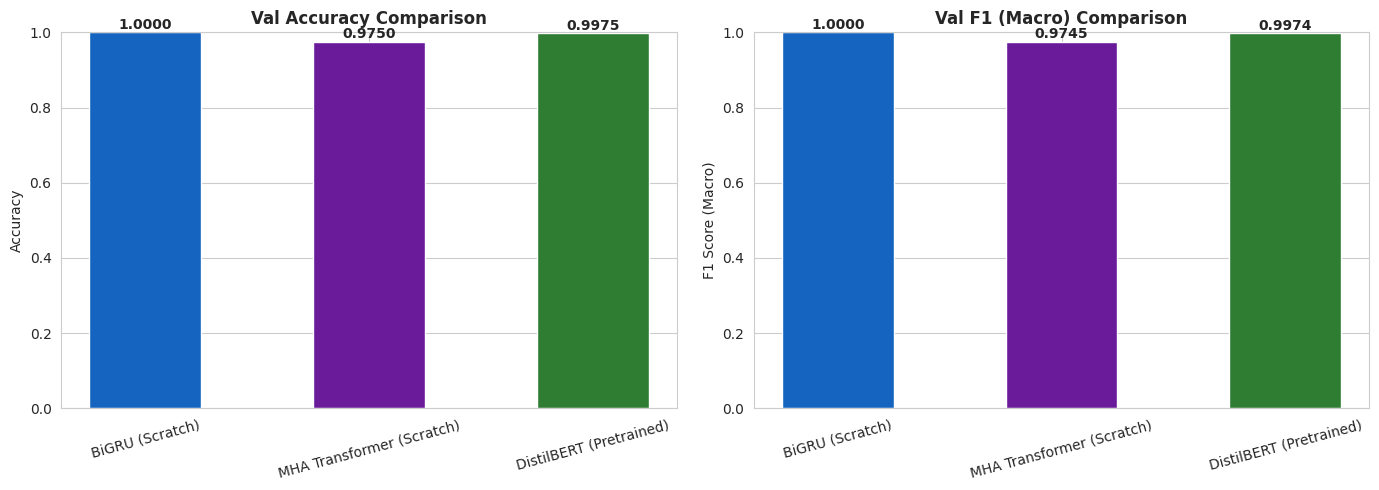

model_comparison.png saved!


In [42]:
# ── Final Model Comparison ───────────────────────────────────
from sklearn.metrics import accuracy_score, f1_score

def get_all_metrics(y_true, y_pred, model_name, val_map3):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='macro', zero_division=0)
    return {
        'Model'    : model_name,
        'Val MAP@3': f'{val_map3:.4f}',
        'Val F1'   : f'{f1:.4f}',
        'Val Acc'  : f'{acc:.4f}',
    }

# Individual scores
bg_map3 = map_at_3(
    [idx_to_letter[i] for i in
     [label2id[a] for a in yt_bg]],
    [[p,'A','B'] for p in yp_bg]
)

# Collect results
results = []
for yt, yp, name in [
    (yt_bg, yp_bg, 'BiGRU (Scratch)'),
    (yt_mh, yp_mh, 'MHA Transformer (Scratch)'),
    (yt_db, yp_db, 'DistilBERT (Pretrained)'),
]:
    acc = accuracy_score(yt, yp)
    f1  = f1_score(yt, yp, average='macro', zero_division=0)
    results.append({
        'Model'    : name,
        'Val Acc'  : round(acc, 4),
        'Val F1'   : round(f1, 4),
    })

results_df = pd.DataFrame(results)
print("\nFinal Comparison Table:")
print(results_df.to_string(index=False))

# ── Bar Chart ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models  = [r['Model'] for r in results]
accs    = [r['Val Acc'] for r in results]
f1s     = [r['Val F1'] for r in results]
colors  = ['#1565C0', '#6A1B9A', '#2E7D32']

# Accuracy
bars1 = axes[0].bar(models, accs, color=colors, width=0.5, edgecolor='white')
axes[0].set_title('Val Accuracy Comparison', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Accuracy')
axes[0].tick_params(axis='x', rotation=15)
for bar, val in zip(bars1, accs):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.01,
                 f'{val:.4f}', ha='center',
                 fontsize=10, fontweight='bold')

# F1
bars2 = axes[1].bar(models, f1s, color=colors, width=0.5, edgecolor='white')
axes[1].set_title('Val F1 (Macro) Comparison', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('F1 Score (Macro)')
axes[1].tick_params(axis='x', rotation=15)
for bar, val in zip(bars2, f1s):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.01,
                 f'{val:.4f}', ha='center',
                 fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()
print("model_comparison.png saved!")